# Classification de la Qualité du Vin

Objectif : prédire si un vin est bon (qualité ≥ 7) ou non à partir de ses caractéristiques physico-chimiques.

Le notebook contient : le prétraitement des données, la modélisation, l'évaluation des modèles et l'optimisation des hyperparamètres.

# Prétraitement des données

## Importation des bibliothèques nécessaires
On importe les bibliothèques de base : NumPy, Pandas, Matplotlib et Seaborn pour les graphiques.

In [1]:
# Importation des bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## Chargement des datasets
On charge les deux fichiers (vin rouge et vin blanc) et on les fusionne en un seul tableau. On ajoute une colonne `type` pour garder l'information sur le type de vin.

In [2]:
# Chargement des datasets
vin_rouge = pd.read_csv("winequality-red.csv", sep=";")
vin_blanc = pd.read_csv("winequality-white.csv", sep=";")

vin_rouge["type"] = "rouge"
vin_blanc["type"] = "blanc"

# Fusion des deux fichiers
dataset = pd.concat([vin_rouge, vin_blanc], ignore_index=True)

# Aperçu
dataset.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,rouge
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge


## Statistiques descriptives
On affiche les dimensions du tableau, les types des colonnes et les statistiques descriptives (moyenne, écart-type, min, max, quartiles).

In [3]:
# Statistiques descriptives
print("Dimensions :", dataset.shape)
print()
dataset.info()

dataset.describe()

Dimensions : (6497, 13)

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


## Valeurs manquantes
On vérifie s'il y a des valeurs manquantes (NaN) dans chaque colonne.

In [4]:
# Valeurs manquantes
print("Valeurs manquantes :")
print(dataset.isnull().sum())

Valeurs manquantes :
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64


## Doublons
On vérifie s'il y a des lignes en double (vins avec exactement les mêmes mesures) et on les supprime pour qu'un même vin ne se retrouve pas à la fois dans le train et dans le test.

In [5]:
# Doublons
print("Nombre de doublons :", dataset.duplicated().sum())

dataset = dataset.drop_duplicates().reset_index(drop=True)
print("Dimensions après suppression :", dataset.shape)

Nombre de doublons : 1177
Dimensions après suppression : (5320, 13)


## Boxplots pour détecter les valeurs aberrantes
Pour détecter les valeurs aberrantes, on trace un boxplot pour chaque variable numérique (chaque variable a son propre graphique car les échelles sont très différentes).

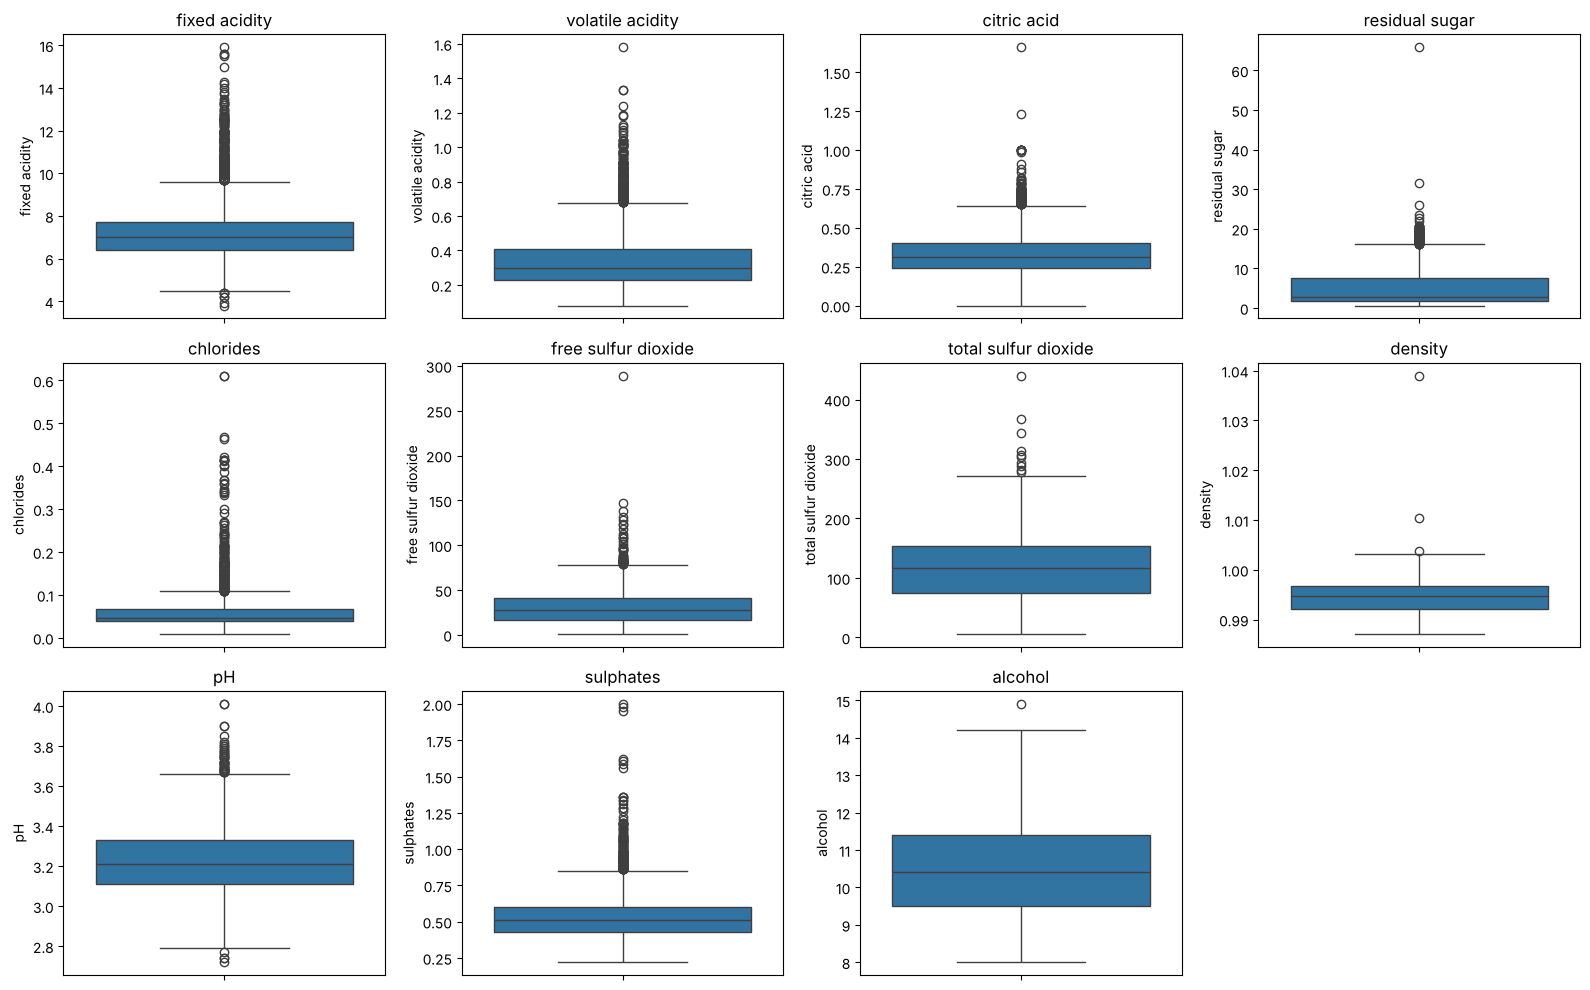

In [6]:
# Boxplots pour détecter les valeurs aberrantes
variables = dataset.drop(["quality", "type"], axis=1).columns

plt.figure(figsize=(16, 10))
for i, col in enumerate(variables):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=dataset[col])
    plt.title(col)
plt.tight_layout()
plt.show()

## Détection des valeurs aberrantes (méthode IQR)
On compte le nombre de valeurs aberrantes par variable avec la règle de l'écart interquartile (IQR) : une valeur est aberrante si elle est en dehors de $[Q_1 - 1.5 \times IQR ; Q_3 + 1.5 \times IQR]$.

In [7]:
# Détection des valeurs aberrantes (méthode IQR)
Q1 = dataset[variables].quantile(0.25)
Q3 = dataset[variables].quantile(0.75)
IQR = Q3 - Q1

aberrantes = (dataset[variables] < Q1 - 1.5 * IQR) | (dataset[variables] > Q3 + 1.5 * IQR)

resultat = pd.DataFrame({
    "Nb aberrantes": aberrantes.sum(),
    "Pourcentage": (aberrantes.mean() * 100).round(2)
})
print(resultat)
print("\nLignes avec au moins une valeur aberrante :", aberrantes.any(axis=1).sum(), "sur", len(dataset))

                      Nb aberrantes  Pourcentage
fixed acidity                   304         5.71
volatile acidity                279         5.24
citric acid                     143         2.69
residual sugar                  141         2.65
chlorides                       237         4.45
free sulfur dioxide              44         0.83
total sulfur dioxide             10         0.19
density                           3         0.06
pH                               49         0.92
sulphates                       163         3.06
alcohol                           1         0.02

Lignes avec au moins une valeur aberrante : 1094 sur 5320


## Commentaire sur les valeurs aberrantes

Les variables qui ont le plus de valeurs aberrantes sont `fixed acidity` (5,7 %), `volatile acidity` (5,2 %), `chlorides` (4,5 %) et `sulphates` (3,1 %). Au total, 1094 vins sur 5320 (environ 21 %) ont au moins une valeur aberrante.

On a décidé de **ne pas les supprimer** : ce sont des mesures chimiques possibles (pas des erreurs de saisie), et supprimer un cinquième des données ferait perdre beaucoup d'informations, surtout que la classe des bons vins est déjà peu nombreuse. On limite leur effet avec la standardisation.

## Encodage de la variable catégorielle
La colonne `type` est une variable catégorielle (texte). On l'encode en nombres : 0 pour le vin rouge et 1 pour le vin blanc. Les autres variables sont déjà numériques.

In [8]:
# Encodage de la variable catégorielle
dataset["type"] = dataset["type"].map({"rouge": 0, "blanc": 1})

print(dataset["type"].value_counts())

type
1    3961
0    1359
Name: count, dtype: int64


## Transformation en classification binaire
On transforme le problème en classification binaire : `bon_vin` vaut 1 si la qualité est ≥ 7 et 0 sinon. On supprime ensuite la colonne `quality`.

In [9]:
# Transformation en classification binaire
dataset["bon_vin"] = (dataset["quality"] >= 7).astype(int)
dataset = dataset.drop("quality", axis=1)

dataset.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,bon_vin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,0,0


## Distribution des classes
On regarde la répartition des deux classes pour voir si le jeu de données est équilibré.

bon_vin
0    4311
1    1009
Name: count, dtype: int64

Bon vin : 0.190 et Non : 0.810


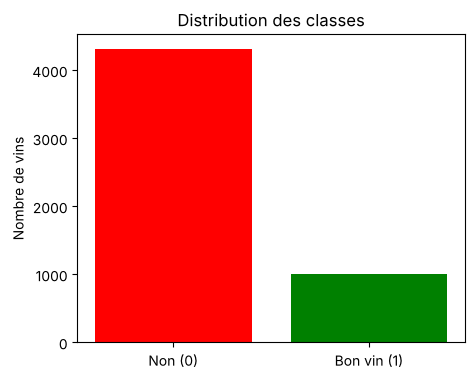

In [10]:
# Distribution des classes
effectifs = dataset["bon_vin"].value_counts()
print(effectifs)
print("\nBon vin : {:.3f} et Non : {:.3f}".format(
    np.mean(dataset["bon_vin"] == 1), np.mean(dataset["bon_vin"] == 0)))

plt.figure(figsize=(5, 4))
plt.bar(["Non (0)", "Bon vin (1)"], effectifs.sort_index().values, color=["red", "green"])
plt.title("Distribution des classes")
plt.ylabel("Nombre de vins")
plt.show()

## Commentaire sur la distribution des classes

Le jeu de données est **déséquilibré** : 4311 vins non bons (81,0 %) contre 1009 bons vins (19,0 %). Donc l'accuracy ne suffit pas pour juger les modèles (un modèle qui répond toujours "non bon" aurait déjà 81 %). Il faudra regarder surtout le rappel et le F1-score de la classe 1.

## Histogrammes des variables
On trace l'histogramme de chaque variable pour voir leur distribution.

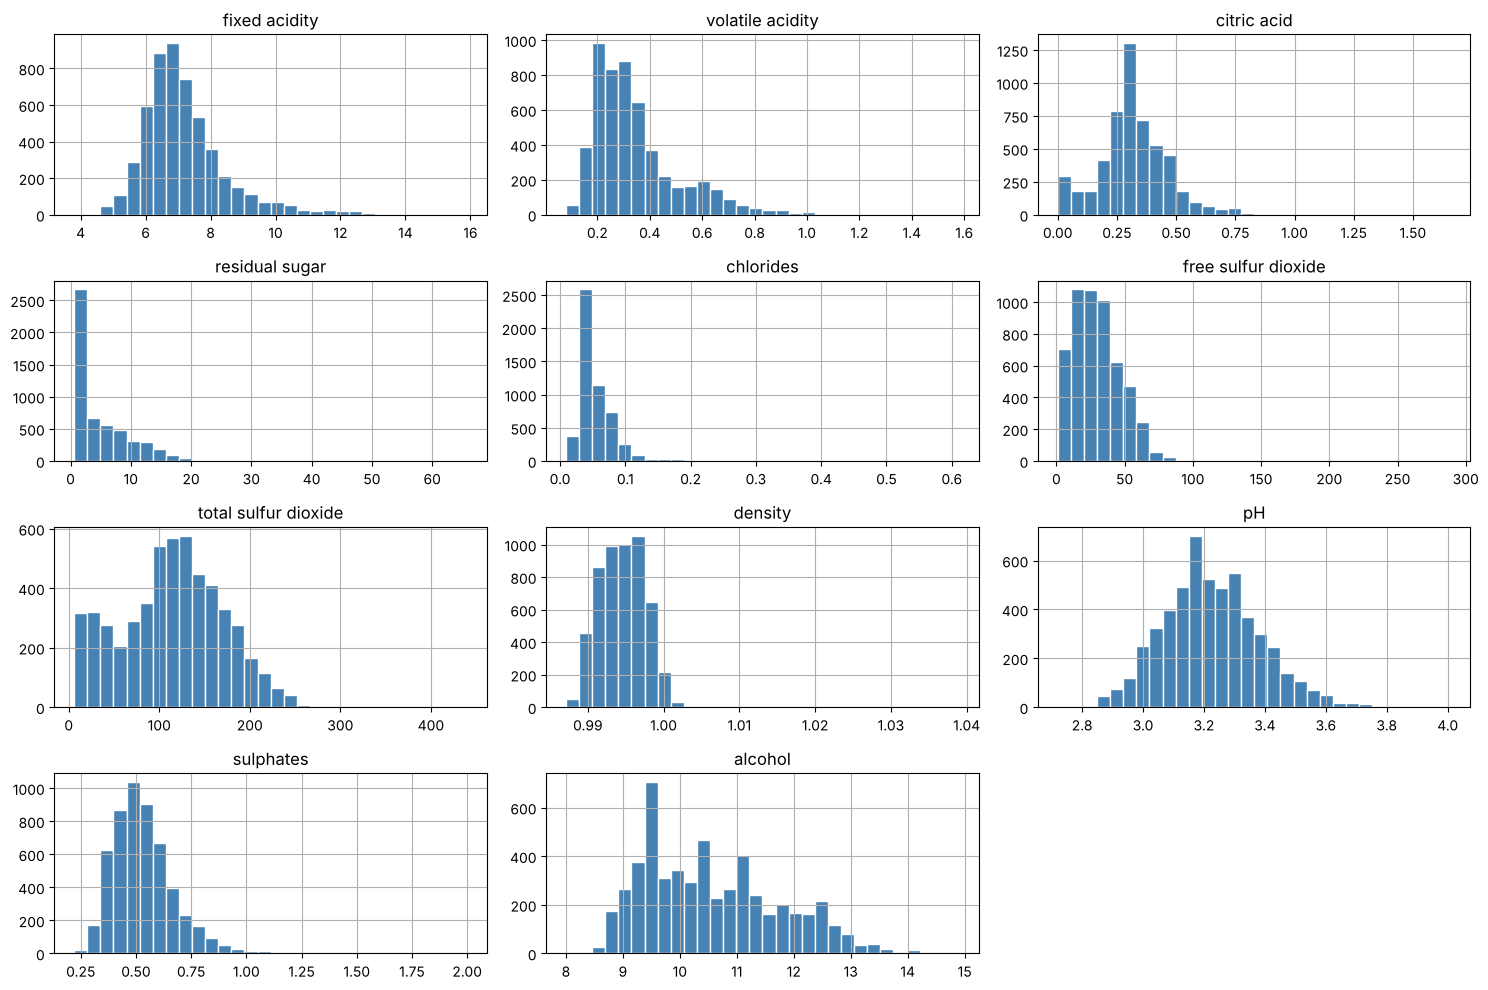

In [11]:
# Histogrammes des variables
dataset[variables].hist(bins=30, figsize=(15, 10), color="steelblue", edgecolor="white")
plt.tight_layout()
plt.show()

## Matrice de corrélation
On calcule la matrice de corrélation de Pearson et on l'affiche avec une heatmap. On affiche aussi la corrélation de chaque variable avec la cible `bon_vin`.

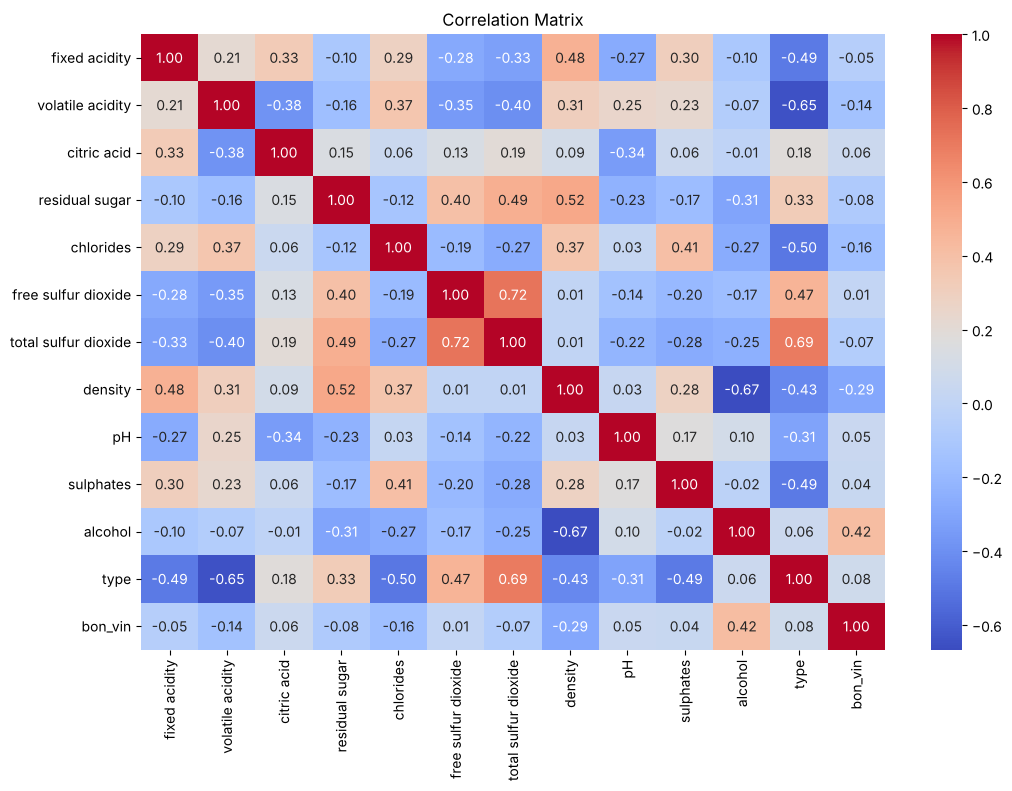

Corrélation avec bon_vin :
alcohol                 0.417743
type                    0.081083
citric acid             0.060672
pH                      0.048330
sulphates               0.036771
free sulfur dioxide     0.011325
fixed acidity          -0.049841
total sulfur dioxide   -0.067307
residual sugar         -0.084868
volatile acidity       -0.144361
chlorides              -0.161027
density                -0.294971
Name: bon_vin, dtype: float64


In [12]:
# Matrice de corrélation
correlation_matrix = dataset.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.show()

print("Corrélation avec bon_vin :")
print(correlation_matrix["bon_vin"].drop("bon_vin").sort_values(ascending=False))

## Commentaire sur les histogrammes et les corrélations

On voit que `alcohol` est la variable la plus corrélée avec `bon_vin` (0.42) : plus un vin contient d'alcool, plus il a de chances d'être bon. Ensuite il y a `density` (−0.29), `chlorides` (−0.16) et `volatile acidity` (−0.14), qui sont liées négativement. À l'inverse `free sulfur dioxide` (0.01), `sulphates` (0.04) et `pH` (0.05) ne sont presque pas liées à la qualité.

Entre elles, certaines variables sont fortement corrélées : `density` et `alcohol` (−0.67), `free sulfur dioxide` et `total sulfur dioxide` (0.72), `type` et `total sulfur dioxide` (0.69), `density` et `residual sugar` (0.52). Elles donnent donc des informations en partie redondantes, ce qui gêne surtout la régression logistique et Naive Bayes (qui suppose les variables indépendantes).

Les histogrammes montrent que plusieurs variables (`residual sugar`, `chlorides`, `free sulfur dioxide`, `volatile acidity`) sont très asymétriques, donc pas du tout gaussiennes.

## Définition de X et y
On sépare les variables explicatives $X$ de la cible $y$ (`bon_vin`).

In [13]:
# Définition de X et y
X = dataset.drop("bon_vin", axis=1)
y = dataset["bon_vin"]

print("X shape :", X.shape)
print("y shape :", y.shape)

X shape : (5320, 12)
y shape : (5320,)


## Séparation train/test (80% train, 20% test)
On sépare les données en 80% pour l'entraînement et 20% pour le test, avec `random_state=42`. On ajoute `stratify=y` pour garder la même proportion de bons vins dans le train et le test (classes déséquilibrées).

In [14]:
# Séparation train/test (80% train, 20% test)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set :", X_train.shape)
print("Test set     :", X_test.shape)

Training set : (4256, 12)
Test set     : (1064, 12)


## Standardisation des données
On standardise les variables (moyenne 0, écart-type 1). On utilise `.fit_transform()` sur le train et uniquement `.transform()` sur le test pour éviter les fuites d'information (data leakage).

In [15]:
# Standardisation des données
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_norm = sc.fit_transform(X_train)
X_test_norm = sc.transform(X_test)

## Sélection de variables - Méthode 1 : filtre par corrélation
**Sélection de variables, méthode 1 (filtre par corrélation)** : on calcule la corrélation de chaque variable avec la cible sur le jeu d'entraînement uniquement, et on garde celles dont la valeur absolue est supérieure ou égale à 0,05.

In [16]:
# Sélection de variables - Méthode 1 : filtre par corrélation
train_complet = pd.concat([X_train, y_train], axis=1)
corr_cible = train_complet.corr()["bon_vin"].drop("bon_vin").abs()

select_corr = corr_cible >= 0.05

print(corr_cible.sort_values(ascending=False))
print("\nVariables gardées :", list(corr_cible[select_corr].index))

alcohol                 0.422594
density                 0.297680
chlorides               0.158681
volatile acidity        0.142750
residual sugar          0.085749
type                    0.080539
total sulfur dioxide    0.074100
citric acid             0.058113
fixed acidity           0.042601
pH                      0.041527
sulphates               0.038398
free sulfur dioxide     0.005473
Name: bon_vin, dtype: float64

Variables gardées : ['volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'density', 'alcohol', 'type']


## Sélection de variables - Méthode 2 : SelectKBest (test ANOVA)
**Méthode 2 (SelectKBest)** : on garde les 6 variables avec le meilleur score du test statistique ANOVA (`f_classif`), qui mesure le lien entre chaque variable et la classe.

In [17]:
# Sélection de variables - Méthode 2 : SelectKBest (test ANOVA)
from sklearn.feature_selection import SelectKBest, f_classif

kbest = SelectKBest(score_func=f_classif, k=6)
kbest.fit(X_train_norm, y_train)

select_kbest = pd.Series(kbest.get_support(), index=X.columns)

scores = pd.Series(kbest.scores_, index=X.columns).sort_values(ascending=False)
print(scores)
print("\nVariables gardées :", list(select_kbest[select_kbest].index))

alcohol                 924.874397
density                 413.612366
chlorides               109.880567
volatile acidity         88.488949
residual sugar           31.511002
type                     27.773924
total sulfur dioxide     23.487119
citric acid              14.414754
fixed acidity             7.734543
pH                        7.348641
sulphates                 6.281294
free sulfur dioxide       0.127433
dtype: float64

Variables gardées : ['volatile acidity', 'residual sugar', 'chlorides', 'density', 'alcohol', 'type']


## Sélection de variables - Méthode 3 : RFE
**Méthode 3 (RFE, élimination récursive)** : on entraîne une régression logistique et on élimine à chaque étape la variable la moins importante, jusqu'à en garder 6.

In [18]:
# Sélection de variables - Méthode 3 : RFE
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

rfe = RFE(estimator=LogisticRegression(), n_features_to_select=6)
rfe.fit(X_train_norm, y_train)

select_rfe = pd.Series(rfe.support_, index=X.columns)

print("Variables gardées :", list(select_rfe[select_rfe].index))

Variables gardées : ['fixed acidity', 'volatile acidity', 'residual sugar', 'density', 'pH', 'alcohol']


## Synthèse de la sélection de variables
On regroupe les résultats des trois méthodes dans un tableau. On garde les variables retenues par **au moins 2 méthodes sur 3**, puis on construit les jeux de données réduits qu'on utilisera pour la modélisation.

In [19]:
# Synthèse de la sélection de variables
selection = pd.DataFrame({
    "Corrélation": select_corr,
    "SelectKBest": select_kbest,
    "RFE": select_rfe
})
selection["Nb de votes"] = selection.sum(axis=1)
print(selection.sort_values("Nb de votes", ascending=False))

# Variables retenues (au moins 2 votes)
masque = (selection["Nb de votes"] >= 2).values
variables_retenues = list(X.columns[masque])
print("\nVariables retenues (", len(variables_retenues), ") :", variables_retenues)

# Jeux de données réduits (déjà standardisés)
X_train_sel = X_train_norm[:, masque]
X_test_sel = X_test_norm[:, masque]

                      Corrélation  SelectKBest    RFE  Nb de votes
volatile acidity             True         True   True            3
residual sugar               True         True   True            3
alcohol                      True         True   True            3
density                      True         True   True            3
type                         True         True  False            2
chlorides                    True         True  False            2
citric acid                  True        False  False            1
fixed acidity               False        False   True            1
pH                          False        False   True            1
total sulfur dioxide         True        False  False            1
free sulfur dioxide         False        False  False            0
sulphates                   False        False  False            0

Variables retenues ( 6 ) : ['volatile acidity', 'residual sugar', 'chlorides', 'density', 'alcohol', 'type']


## Commentaire sur la sélection de variables

Les trois méthodes sont d'accord sur 4 variables : `alcohol`, `density`, `volatile acidity` et `residual sugar`. Avec `type` et `chlorides` (retenues par 2 méthodes sur 3), on garde **6 variables sur 12** pour la suite.

Les variables éliminées sont `citric acid`, `fixed acidity`, `pH` et `total sulfur dioxide` (1 vote), et `free sulfur dioxide` et `sulphates` (0 vote) : elles ont toutes une corrélation faible avec la cible (moins de 0.08 en valeur absolue), donc elles apportent peu d'information pour prédire la qualité.

# Modélisation

## Justification du choix des modèles

- **Régression logistique** : c'est un modèle **linéaire** (la frontière entre les deux classes est un hyperplan). Il est simple, rapide et interprétable, donc c'est une bonne référence. Il peut manquer de souplesse si la relation entre les variables et la qualité n'est pas linéaire. Il s'adapte bien à des variables continues standardisées, mais les variables corrélées entre elles rendent ses coefficients moins stables.
- **k-NN** : modèle **non linéaire** et non paramétrique, qui ne fait aucune hypothèse sur la forme des données. Il est sensible à l'échelle des variables (d'où la standardisation) et au bruit : avec un petit $k$ il a un faible biais mais une forte variance.
- **Arbre de décision** : modèle **non linéaire** qui ne demande aucune hypothèse sur la distribution des variables, n'a pas besoin de normalisation et est peu sensible aux valeurs aberrantes. Il est facile à interpréter mais a tendance au sur-apprentissage (forte variance) quand il est profond.
- **Naive Bayes (gaussien)** : modèle probabiliste très rapide qui suppose que les variables sont **indépendantes** entre elles et suivent une loi normale. Ici ces hypothèses ne sont pas vraiment respectées (variables corrélées, distributions asymétriques), donc on s'attend à un biais assez élevé.
- **SVM** : avec le noyau RBF, il est **non linéaire** et peut trouver des frontières complexes. Il marche bien avec des variables continues standardisées, et les paramètres $C$ et $\gamma$ permettent de régler le compromis biais/variance. Il est plus long à entraîner que les autres.

On entraîne les cinq modèles avec leurs paramètres par défaut (sauf $k=5$ pour le k-NN), sur les données standardisées et réduites (variables retenues à l'étape de sélection de variables).

## Régression logistique
On entraîne la régression logistique puis on prédit sur le jeu de test (classes et probabilités, les probabilités serviront pour la courbe ROC).

In [20]:
# Régression logistique
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42)
lr.fit(X_train_sel, y_train)

y_pred_lr = lr.predict(X_test_sel)
y_prob_lr = lr.predict_proba(X_test_sel)[:, 1]

## K-NN (k=5)
On entraîne le k-NN avec $k=5$ voisins.

In [21]:
# K-NN (k=5)
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_sel, y_train)

y_pred_knn = knn.predict(X_test_sel)
y_prob_knn = knn.predict_proba(X_test_sel)[:, 1]

## Arbre de décision
On entraîne l'arbre de décision (sans limite de profondeur pour l'instant).

In [22]:
# Arbre de décision
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_sel, y_train)

y_pred_dt = dt.predict(X_test_sel)
y_prob_dt = dt.predict_proba(X_test_sel)[:, 1]

## Naive Bayes
On entraîne le classifieur Naive Bayes gaussien.

In [23]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train_sel, y_train)

y_pred_nb = gnb.predict(X_test_sel)
y_prob_nb = gnb.predict_proba(X_test_sel)[:, 1]

## SVM (noyau RBF)
On entraîne le SVM avec le noyau radial (rbf). On met `probability=True` pour pouvoir calculer les probabilités et tracer la courbe ROC.

In [24]:
# SVM (noyau RBF)
from sklearn.svm import SVC

svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_sel, y_train)

y_pred_svm = svm.predict(X_test_sel)
y_prob_svm = svm.predict_proba(X_test_sel)[:, 1]

# Évaluation des modèles

## Matrices de confusion et rapports de classification
On affiche pour chaque modèle la matrice de confusion et le rapport de classification (précision, rappel, F1-score et accuracy).

In [25]:
# Matrices de confusion et rapports de classification
from sklearn.metrics import confusion_matrix, classification_report

print("************* Régression Logistique *************")
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

print("\n************* K-NN (k=5) *************")
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

print("\n************* Arbre de Décision *************")
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

print("\n************* Naive Bayes *************")
print(confusion_matrix(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

print("\n************* SVM (RBF) *************")
print(confusion_matrix(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

************* Régression Logistique *************
[[810  52]
 [153  49]]
              precision    recall  f1-score   support

           0       0.84      0.94      0.89       862
           1       0.49      0.24      0.32       202

    accuracy                           0.81      1064
   macro avg       0.66      0.59      0.61      1064
weighted avg       0.77      0.81      0.78      1064


************* K-NN (k=5) *************
[[782  80]
 [137  65]]
              precision    recall  f1-score   support

           0       0.85      0.91      0.88       862
           1       0.45      0.32      0.37       202

    accuracy                           0.80      1064
   macro avg       0.65      0.61      0.63      1064
weighted avg       0.77      0.80      0.78      1064


************* Arbre de Décision *************
[[741 121]
 [116  86]]
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       862
           1       0.42      0.

## Matrices de confusion (graphiques)
On affiche les matrices de confusion sous forme de graphique pour mieux les comparer.

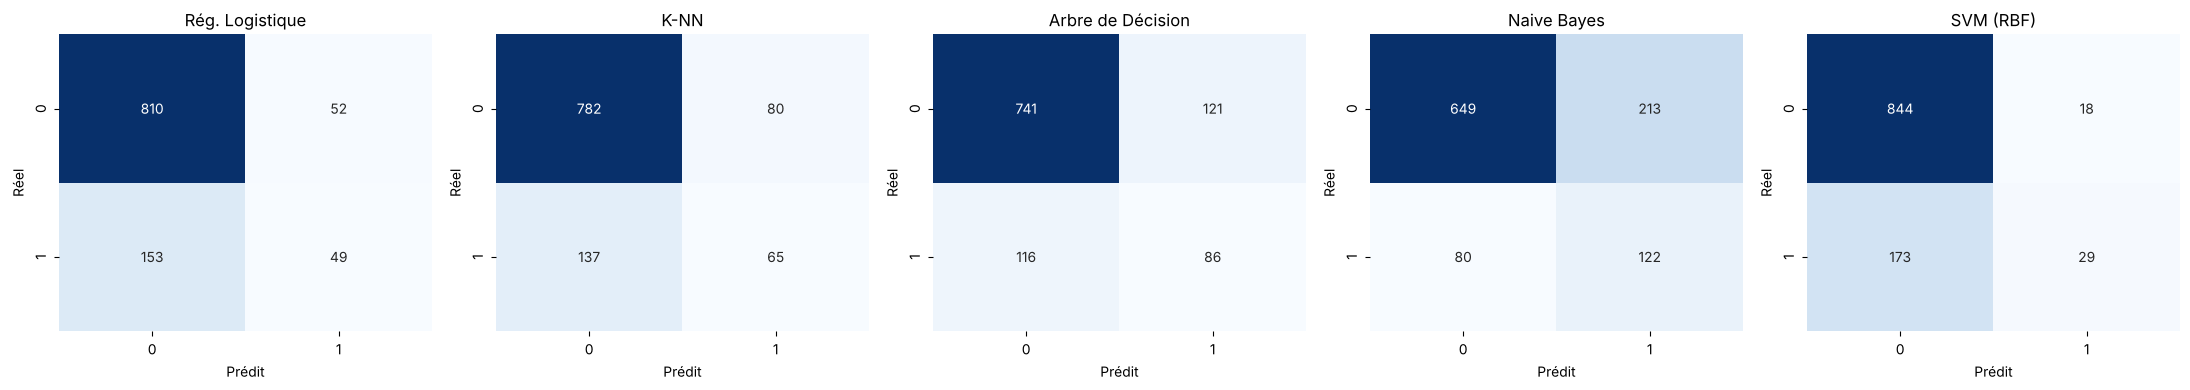

In [26]:
# Matrices de confusion (graphiques)
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Rég. Logistique")

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("K-NN")

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set_title("Arbre de Décision")

sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[3])
axes[3].set_title("Naive Bayes")

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[4])
axes[4].set_title("SVM (RBF)")

for ax in axes:
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()

## Courbes ROC et AUC
On trace les courbes ROC des cinq modèles sur le même graphique et on calcule l'AUC de chacun.

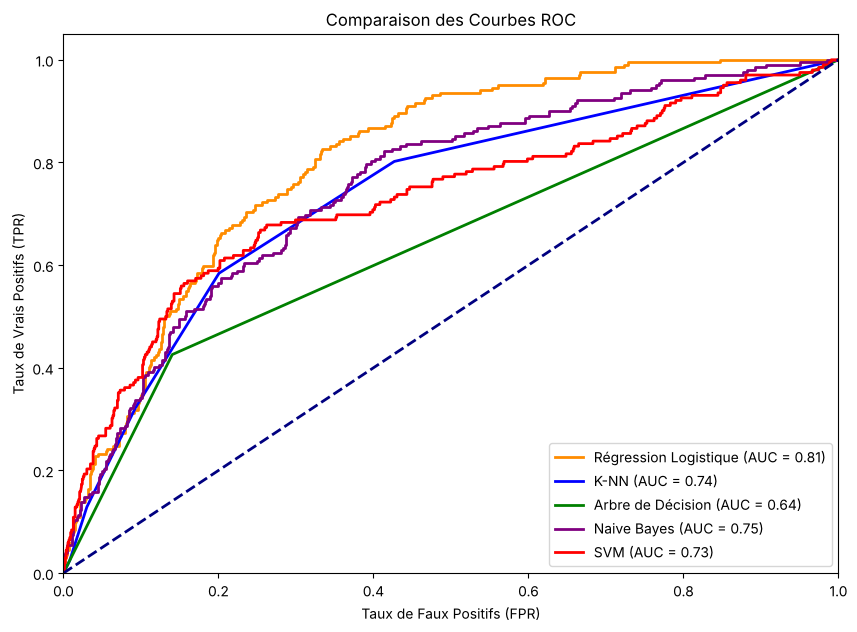

In [27]:
# Courbes ROC et AUC
from sklearn.metrics import roc_curve, auc

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(10, 7))

plt.plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label='Régression Logistique (AUC = %0.2f)' % roc_auc_lr)
plt.plot(fpr_knn, tpr_knn, color='blue', lw=2, label='K-NN (AUC = %0.2f)' % roc_auc_knn)
plt.plot(fpr_dt, tpr_dt, color='green', lw=2, label='Arbre de Décision (AUC = %0.2f)' % roc_auc_dt)
plt.plot(fpr_nb, tpr_nb, color='purple', lw=2, label='Naive Bayes (AUC = %0.2f)' % roc_auc_nb)
plt.plot(fpr_svm, tpr_svm, color='red', lw=2, label='SVM (AUC = %0.2f)' % roc_auc_svm)

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Ligne du hasard
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)')
plt.ylabel('Taux de Vrais Positifs (TPR)')
plt.title('Comparaison des Courbes ROC')
plt.legend(loc="lower right")
plt.show()

## Tableau récapitulatif
On rassemble les résultats dans un tableau comparatif. On ajoute le F1-score sur le train pour comparer avec le F1-score sur le test (cela permet de voir le sur-apprentissage).

In [28]:
# Tableau récapitulatif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Régression Logistique", "K-NN (k=5)", "Arbre de Décision", "Naive Bayes", "SVM (RBF)"],
    "Accuracy": [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_knn),
                 accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_nb),
                 accuracy_score(y_test, y_pred_svm)],
    "Precision": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_knn),
                  precision_score(y_test, y_pred_dt), precision_score(y_test, y_pred_nb),
                  precision_score(y_test, y_pred_svm)],
    "Recall": [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_knn),
               recall_score(y_test, y_pred_dt), recall_score(y_test, y_pred_nb),
               recall_score(y_test, y_pred_svm)],
    "F1 test": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_knn),
                f1_score(y_test, y_pred_dt), f1_score(y_test, y_pred_nb),
                f1_score(y_test, y_pred_svm)],
    "AUC": [roc_auc_lr, roc_auc_knn, roc_auc_dt, roc_auc_nb, roc_auc_svm],
    "F1 train": [f1_score(y_train, lr.predict(X_train_sel)), f1_score(y_train, knn.predict(X_train_sel)),
                 f1_score(y_train, dt.predict(X_train_sel)), f1_score(y_train, gnb.predict(X_train_sel)),
                 f1_score(y_train, svm.predict(X_train_sel))]
}).round(3)

results

,Model,Accuracy,Precision,Recall,F1 test,AUC,F1 train
0,Régression Logistique,0.807,0.485,0.243,0.323,0.806,0.357
1,K-NN (k=5),0.796,0.448,0.322,0.375,0.738,0.604
2,Arbre de Décision,0.777,0.415,0.426,0.421,0.643,1.000
3,Naive Bayes,0.725,0.364,0.604,0.454,0.753,0.489
4,SVM (RBF),0.820,0.617,0.144,0.233,0.728,0.298


## Commentaire sur la comparaison des modèles

**Accuracy** : elle est proche pour presque tous les modèles (0.78 à 0.82, sauf Naive Bayes à 0.72), donc elle ne permet pas de bien les départager à cause du déséquilibre des classes. On regarde plutôt le rappel de la classe 1, le F1-score et l'AUC.

**Régression logistique et SVM** : leur rappel est très faible (0.24 et 0.14), ils ratent la grande majorité des bons vins. Leur F1 train et leur F1 test sont proches et faibles (0.36 / 0.32 pour la régression logistique, 0.30 / 0.23 pour le SVM) : ils sous-apprennent (**biais élevé**). La régression logistique a quand même le meilleur AUC (0.806), donc elle classe bien les vins entre eux, mais le seuil de 0.5 est trop haut pour la classe minoritaire.

**Naive Bayes** : il a le meilleur F1 (0.45) et le meilleur rappel (0.60), avec un F1 train presque identique (0.49) : pas de sur-apprentissage. Sa précision est par contre faible (0.36), il fait beaucoup de faux positifs.

**Arbre de décision** : F1 de 0.42, mais son F1 train vaut 1.0 : il apprend le jeu d'entraînement par cœur, c'est du sur-apprentissage (**variance élevée**). Son AUC (0.643) est la plus faible car un arbre sans limite donne des probabilités presque toujours égales à 0 ou 1.

**K-NN** : F1 de 0.38 avec un écart train/test important (0.60 / 0.38), il sur-apprend aussi.

**Linéaire vs non linéaire** : les modèles non linéaires (k-NN, arbre, SVM) ne font pas mieux que la régression logistique, et ils sur-apprennent pour le k-NN et l'arbre. Les variables physico-chimiques ne permettent pas de séparer facilement les bons vins, quel que soit le type de modèle.

**Conclusion avant optimisation** : Naive Bayes est le meilleur compromis biais/variance (meilleur F1, pas de sur-apprentissage), la régression logistique a le meilleur AUC, et l'arbre et le k-NN sur-apprennent.

# Optimisation des hyperparamètres

On utilise **Grid Search** (recherche exhaustive) pour la régression logistique, le k-NN et l'arbre de décision, qui ont peu d'hyperparamètres, et **Random Search** (recherche aléatoire) pour le SVM, qui a des paramètres continus ($C$ et $\gamma$). Le Naive Bayes n'a pratiquement pas d'hyperparamètre à régler. La validation croisée est à 5 plis (`cv=5`) sur le jeu d'entraînement, et on optimise le **F1-score** (et non l'accuracy) à cause du déséquilibre des classes.

## Grid Search - Régression logistique
Grid Search pour la régression logistique : on teste plusieurs valeurs du paramètre de régularisation $C$.

In [29]:
# Grid Search - Régression logistique
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(LogisticRegression(random_state=42), param_grid_lr, cv=5, scoring='f1')
grid_lr.fit(X_train_sel, y_train)

print("Meilleurs paramètres :", grid_lr.best_params_)
print("Meilleur F1 (validation croisée) : %.3f" % grid_lr.best_score_)

Meilleurs paramètres : {'C': 100}
Meilleur F1 (validation croisée) : 0.359


## Grid Search - K-NN
Grid Search pour le k-NN : on teste le nombre de voisins, le type de poids et la distance.

In [30]:
# Grid Search - K-NN
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring='f1')
grid_knn.fit(X_train_sel, y_train)

print("Meilleurs paramètres :", grid_knn.best_params_)
print("Meilleur F1 (validation croisée) : %.3f" % grid_knn.best_score_)

Meilleurs paramètres : {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
Meilleur F1 (validation croisée) : 0.457


## Grid Search - Arbre de décision
Grid Search pour l'arbre de décision : on limite la profondeur et la taille des feuilles pour réduire le sur-apprentissage.

In [31]:
# Grid Search - Arbre de décision
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=5, scoring='f1')
grid_dt.fit(X_train_sel, y_train)

print("Meilleurs paramètres :", grid_dt.best_params_)
print("Meilleur F1 (validation croisée) : %.3f" % grid_dt.best_score_)

Meilleurs paramètres : {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}
Meilleur F1 (validation croisée) : 0.424


## Random Search - SVM
Random Search pour le SVM : au lieu de tester toutes les combinaisons, on tire 20 couples ($C$, $\gamma$) au hasard dans des intervalles (échelle logarithmique).

In [32]:
# Random Search - SVM
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_dist_svm = {
    'C': loguniform(1e-1, 1e2),
    'gamma': loguniform(1e-3, 1e0)
}

rand_svm = RandomizedSearchCV(SVC(kernel='rbf', probability=True, random_state=42),
                              param_dist_svm, n_iter=20, cv=5, scoring='f1', random_state=42)
rand_svm.fit(X_train_sel, y_train)

print("Meilleurs paramètres :", rand_svm.best_params_)
print("Meilleur F1 (validation croisée) : %.3f" % rand_svm.best_score_)

Meilleurs paramètres : {'C': np.float64(78.86714129990483), 'gamma': np.float64(0.2661901888489056)}
Meilleur F1 (validation croisée) : 0.386


## Validation croisée (k-fold, k=5) des modèles optimisés
On évalue les modèles optimisés par validation croisée k-fold (5 plis) sur le jeu d'entraînement : on affiche le F1 moyen et l'écart-type sur les 5 plis (un écart-type faible veut dire que le modèle est stable).

In [33]:
# Validation croisée (k-fold, k=5) des modèles optimisés
from sklearn.model_selection import cross_val_score

best_lr = grid_lr.best_estimator_
best_knn = grid_knn.best_estimator_
best_dt = grid_dt.best_estimator_
best_svm = rand_svm.best_estimator_

cv_lr = cross_val_score(best_lr, X_train_sel, y_train, cv=5, scoring='f1')
cv_knn = cross_val_score(best_knn, X_train_sel, y_train, cv=5, scoring='f1')
cv_dt = cross_val_score(best_dt, X_train_sel, y_train, cv=5, scoring='f1')
cv_nb = cross_val_score(gnb, X_train_sel, y_train, cv=5, scoring='f1')
cv_svm = cross_val_score(best_svm, X_train_sel, y_train, cv=5, scoring='f1')

print("******** F1 en validation croisée (5-fold) ********")
print("Régression Logistique optimisée : %.3f (+/- %.3f)" % (cv_lr.mean(), cv_lr.std()))
print("K-NN optimisé                   : %.3f (+/- %.3f)" % (cv_knn.mean(), cv_knn.std()))
print("Arbre de Décision optimisé      : %.3f (+/- %.3f)" % (cv_dt.mean(), cv_dt.std()))
print("Naive Bayes (non optimisé)      : %.3f (+/- %.3f)" % (cv_nb.mean(), cv_nb.std()))
print("SVM optimisé                    : %.3f (+/- %.3f)" % (cv_svm.mean(), cv_svm.std()))

******** F1 en validation croisée (5-fold) ********
Régression Logistique optimisée : 0.359 (+/- 0.027)
K-NN optimisé                   : 0.457 (+/- 0.030)
Arbre de Décision optimisé      : 0.424 (+/- 0.024)
Naive Bayes (non optimisé)      : 0.488 (+/- 0.018)
SVM optimisé                    : 0.386 (+/- 0.022)


## Évaluation des modèles optimisés sur le jeu de test
On évalue enfin les modèles optimisés sur le jeu de test et on les rassemble dans un tableau final.

In [34]:
# Évaluation des modèles optimisés sur le jeu de test
y_pred_lr_opt = best_lr.predict(X_test_sel)
y_pred_knn_opt = best_knn.predict(X_test_sel)
y_pred_dt_opt = best_dt.predict(X_test_sel)
y_pred_svm_opt = best_svm.predict(X_test_sel)

# Calcul de l'AUC des modèles optimisés
fpr, tpr, _ = roc_curve(y_test, best_lr.predict_proba(X_test_sel)[:, 1])
auc_lr_opt = auc(fpr, tpr)

fpr, tpr, _ = roc_curve(y_test, best_knn.predict_proba(X_test_sel)[:, 1])
auc_knn_opt = auc(fpr, tpr)

fpr, tpr, _ = roc_curve(y_test, best_dt.predict_proba(X_test_sel)[:, 1])
auc_dt_opt = auc(fpr, tpr)

fpr, tpr, _ = roc_curve(y_test, best_svm.predict_proba(X_test_sel)[:, 1])
auc_svm_opt = auc(fpr, tpr)

results_opt = pd.DataFrame({
    "Model": ["Régression Logistique", "K-NN", "Arbre de Décision", "Naive Bayes (non optimisé)", "SVM (RBF)"],
    "Accuracy": [accuracy_score(y_test, y_pred_lr_opt), accuracy_score(y_test, y_pred_knn_opt),
                 accuracy_score(y_test, y_pred_dt_opt), accuracy_score(y_test, y_pred_nb),
                 accuracy_score(y_test, y_pred_svm_opt)],
    "Precision": [precision_score(y_test, y_pred_lr_opt), precision_score(y_test, y_pred_knn_opt),
                  precision_score(y_test, y_pred_dt_opt), precision_score(y_test, y_pred_nb),
                  precision_score(y_test, y_pred_svm_opt)],
    "Recall": [recall_score(y_test, y_pred_lr_opt), recall_score(y_test, y_pred_knn_opt),
               recall_score(y_test, y_pred_dt_opt), recall_score(y_test, y_pred_nb),
               recall_score(y_test, y_pred_svm_opt)],
    "F1 test": [f1_score(y_test, y_pred_lr_opt), f1_score(y_test, y_pred_knn_opt),
                f1_score(y_test, y_pred_dt_opt), f1_score(y_test, y_pred_nb),
                f1_score(y_test, y_pred_svm_opt)],
    "AUC": [auc_lr_opt, auc_knn_opt, auc_dt_opt, roc_auc_nb, auc_svm_opt],
    "F1 CV (5-fold)": [cv_lr.mean(), cv_knn.mean(), cv_dt.mean(), cv_nb.mean(), cv_svm.mean()],
    "F1 train": [f1_score(y_train, best_lr.predict(X_train_sel)), f1_score(y_train, best_knn.predict(X_train_sel)),
                 f1_score(y_train, best_dt.predict(X_train_sel)), f1_score(y_train, gnb.predict(X_train_sel)),
                 f1_score(y_train, best_svm.predict(X_train_sel))]
}).round(3)

results_opt

,Model,Accuracy,Precision,Recall,F1 test,AUC,F1 CV (5-fold),F1 train
0,Régression Logistique,0.806,0.480,0.243,0.322,0.806,0.359,0.358
1,K-NN,0.806,0.485,0.322,0.387,0.763,0.457,1.000
2,Arbre de Décision,0.777,0.415,0.426,0.421,0.643,0.424,1.000
3,Naive Bayes (non optimisé),0.725,0.364,0.604,0.454,0.753,0.488,0.489
4,SVM (RBF),0.823,0.588,0.233,0.333,0.766,0.386,0.442


# Prise en compte du déséquilibre des classes

Même après optimisation, les modèles détectent peu de bons vins : le rappel reste entre 0.23 et 0.43, sauf pour Naive Bayes (0.60). Cela vient du déséquilibre des classes (19 % de bons vins) : les modèles sont entraînés pour minimiser l'erreur globale, donc ils ont naturellement tendance à privilégier la classe majoritaire.

On teste ici une approche différente : `class_weight="balanced"`, qui pénalise davantage les erreurs commises sur la classe minoritaire pendant l'entraînement (le poids de chaque classe est inversement proportionnel à sa fréquence). On applique ça aux modèles qui supportent ce paramètre : régression logistique, arbre de décision et SVM, en gardant les meilleurs hyperparamètres trouvés précédemment par Grid/Random Search. Le k-NN et le Naive Bayes ne sont pas concernés : le k-NN n'a pas de paramètre `class_weight` (c'est un vote entre voisins, pas une fonction de coût), et Naive Bayes fonctionne avec des probabilités a priori plutôt qu'avec des poids de classe.

In [35]:
# Modèles avec class_weight="balanced" (mêmes hyperparamètres que les modèles optimisés)
lr_bal = LogisticRegression(random_state=42, C=grid_lr.best_params_['C'], class_weight='balanced')
lr_bal.fit(X_train_sel, y_train)
y_pred_lr_bal = lr_bal.predict(X_test_sel)

dt_bal = DecisionTreeClassifier(
    random_state=42,
    criterion=grid_dt.best_params_['criterion'],
    max_depth=grid_dt.best_params_['max_depth'],
    min_samples_leaf=grid_dt.best_params_['min_samples_leaf'],
    class_weight='balanced'
)
dt_bal.fit(X_train_sel, y_train)
y_pred_dt_bal = dt_bal.predict(X_test_sel)

svm_bal = SVC(
    kernel='rbf',
    C=rand_svm.best_params_['C'],
    gamma=rand_svm.best_params_['gamma'],
    probability=True,
    random_state=42,
    class_weight='balanced'
)
svm_bal.fit(X_train_sel, y_train)
y_pred_svm_bal = svm_bal.predict(X_test_sel)

print("************* Régression Logistique (balanced) *************")
print(confusion_matrix(y_test, y_pred_lr_bal))
print(classification_report(y_test, y_pred_lr_bal))

print("\n************* Arbre de Décision (balanced) *************")
print(confusion_matrix(y_test, y_pred_dt_bal))
print(classification_report(y_test, y_pred_dt_bal))

print("\n************* SVM RBF (balanced) *************")
print(confusion_matrix(y_test, y_pred_svm_bal))
print(classification_report(y_test, y_pred_svm_bal))

************* Régression Logistique (balanced) *************
[[602 260]
 [ 48 154]]
              precision    recall  f1-score   support

           0       0.93      0.70      0.80       862
           1       0.37      0.76      0.50       202

    accuracy                           0.71      1064
   macro avg       0.65      0.73      0.65      1064
weighted avg       0.82      0.71      0.74      1064


************* Arbre de Décision (balanced) *************
[[758 104]
 [121  81]]
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       862
           1       0.44      0.40      0.42       202

    accuracy                           0.79      1064
   macro avg       0.65      0.64      0.64      1064
weighted avg       0.78      0.79      0.78      1064


************* SVM RBF (balanced) *************
[[591 271]
 [ 43 159]]
              precision    recall  f1-score   support

           0       0.93      0.69      0.79       862
 

In [36]:
# Comparaison avant / après class_weight="balanced"
comparaison_balanced = pd.DataFrame({
    "Modèle": ["Régression Logistique", "Arbre de Décision", "SVM (RBF)"],
    "Recall (optimisé)": [
        recall_score(y_test, y_pred_lr_opt),
        recall_score(y_test, y_pred_dt_opt),
        recall_score(y_test, y_pred_svm_opt)
    ],
    "Recall (balanced)": [
        recall_score(y_test, y_pred_lr_bal),
        recall_score(y_test, y_pred_dt_bal),
        recall_score(y_test, y_pred_svm_bal)
    ],
    "F1 (optimisé)": [
        f1_score(y_test, y_pred_lr_opt),
        f1_score(y_test, y_pred_dt_opt),
        f1_score(y_test, y_pred_svm_opt)
    ],
    "F1 (balanced)": [
        f1_score(y_test, y_pred_lr_bal),
        f1_score(y_test, y_pred_dt_bal),
        f1_score(y_test, y_pred_svm_bal)
    ],
    "Accuracy (balanced)": [
        accuracy_score(y_test, y_pred_lr_bal),
        accuracy_score(y_test, y_pred_dt_bal),
        accuracy_score(y_test, y_pred_svm_bal)
    ]
}).round(3)

comparaison_balanced

,Modèle,Recall (optimisé),Recall (balanced),F1 (optimisé),F1 (balanced),Accuracy (balanced)
0,Régression Logistique,0.243,0.762,0.322,0.500,0.711
1,Arbre de Décision,0.426,0.401,0.421,0.419,0.789
2,SVM (RBF),0.233,0.787,0.333,0.503,0.705


## Commentaire sur la prise en compte du déséquilibre

Le `class_weight="balanced"` change nettement le comportement des modèles concernés :

- **Régression logistique** : le rappel passe de 0.243 à **0.762** (le modèle détecte 3 fois plus de bons vins), et le F1-score progresse de 0.322 à **0.500**. En contrepartie, l'accuracy chute de 0.806 à 0.711 : le modèle fait beaucoup plus de faux positifs (260 sur le jeu de test).
- **SVM (RBF)** : même tendance, rappel de 0.233 à **0.787**, F1 de 0.333 à **0.503**, accuracy de 0.823 à 0.705.
- **Arbre de décision** : presque aucun effet (F1 de 0.421 à 0.419, rappel de 0.426 à 0.401) car l'arbre sans limite de profondeur crée de toute façon des feuilles pures, le poids des classes ne change donc presque rien.

Le `class_weight="balanced"` illustre bien le compromis précision/rappel : on échange de l'accuracy contre la capacité à détecter les bons vins. Ici ça vaut le coup : la régression logistique et le SVM pondérés ont le **meilleur F1 de tout le projet** (0.50), devant Naive Bayes (0.45), avec un rappel bien supérieur à tout ce qui a été testé avant.

## Commentaire sur les modèles optimisés et conclusion

**Effet de l'optimisation**
- **Régression logistique** : le meilleur paramètre est $C=100$ (moins de régularisation), mais le F1 test ne bouge presque pas (0.323 → 0.322). Le problème vient du déséquilibre, pas du réglage.
- **K-NN** : `n_neighbors=7`, distance de Manhattan et poids selon la distance. Le F1 test passe de 0.375 à 0.387 et l'AUC de 0.738 à 0.763, mais le F1 train vaut 1.0 (avec `weights='distance'` chaque point d'entraînement est son propre voisin) et le F1 en validation croisée (0.457) est assez loin du F1 test.
- **Arbre de décision** : le Grid Search garde les paramètres par défaut (pas de limite de profondeur), donc pas de changement (F1 test 0.421). Il reste en sur-apprentissage (F1 train = 1.0).
- **SVM** : le Random Search trouve $C \approx 79$ et $\gamma \approx 0.27$. Le F1 test passe de 0.233 à 0.333, le rappel de 0.14 à 0.23 et l'AUC de 0.728 à 0.766. C'est mieux mais ça reste faible.
- **Naive Bayes** : pas optimisé (F1 0.454).

**Validation croisée** : le F1 en validation croisée est proche du F1 test pour la plupart des modèles (arbre 0.424 contre 0.421, Naive Bayes 0.488 contre 0.454, régression logistique 0.359 contre 0.322, SVM 0.386 contre 0.333). L'écart est plus grand pour le k-NN (0.457 contre 0.387). Les écarts-types sont faibles (au maximum 0.030), donc les résultats ne dépendent pas d'un découpage chanceux.

**Grid Search vs Random Search** : le Grid Search teste toutes les combinaisons (exhaustif, mais long quand il y a beaucoup de paramètres). Le Random Search teste seulement 20 combinaisons tirées au hasard : c'est plus rapide et adapté aux paramètres continus comme $C$ et $\gamma$.

**Sans pondération des classes**, le meilleur modèle est **Naive Bayes** : meilleur F1 test (0.454), meilleur F1 en validation croisée (0.488) et meilleur rappel (0.60), sans sur-apprentissage (F1 train 0.489).

**Modèle retenu : la régression logistique avec `class_weight="balanced"`.** Elle a le meilleur F1 du projet (0.500, à égalité avec le SVM pondéré à 0.503) et un rappel de 0.76. On la préfère au SVM car elle est plus simple, plus rapide et interprétable, pour un score équivalent.

**Compromis biais/variance** : la régression logistique, le SVM et Naive Bayes ont un biais élevé (scores faibles, train ≈ test), l'arbre et le k-NN ont une variance élevée (F1 train 1.0). La suppression des doublons était importante : sans elle, un même vin pouvait se retrouver dans le train et le test, ce qui avantage justement les modèles qui retiennent les exemples (k-NN, arbre).

**Limite** : même le meilleur modèle a une précision faible (0.37) : pour détecter 3 bons vins sur 4, il faut accepter beaucoup de fausses alertes. Les 12 mesures physico-chimiques ne suffisent pas à séparer parfaitement les bons vins des autres.